# Project 1: COVID-19 Data Analysis Dashboard 

In [1]:
%pip install pandas numpy matplotlib seaborn plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 15.2 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.7 MB 4.5 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.7 MB 4.5 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/9.7 MB 4.3 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.7 MB 4.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.7 MB 4.1 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.7 MB 4.1 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.7 MB 3.9 MB/s eta 0:00:01
   ---------------------------- ----------- 6.8/9.7 MB 3.7 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.7 MB 3.6 MB/s eta 0:00:01
   --------------------------------- ------ 8.1/9.7 MB 3.6 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.7 MB 3.8 MB/s eta 0:00:01
   ---------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\anshu\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
url = "https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Dataset loaded successfully!
Shape: (617667, 61)
Columns: ['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'total_bo

In [16]:
df.columns = df.columns.str.strip().str.lower()

def find_column(options):
    for col in options:
        if col in df.columns:
            return col
    return None

country_col = find_column(["location", "country", "entity"])
date_col = find_column(["date", "day"])
cases_col = find_column(["total_cases", "confirmed", "cases"])
deaths_col = find_column(["total_deaths", "deaths"])
vaccine_col = find_column([
    "people_vaccinated", "total_people_vaccinated",
    "total_vaccinations", "people_vaccinated_per_hundred"
])

print("Country column:", country_col)
print("Date column:", date_col)
print("Cases column:", cases_col)
print("Deaths column:", deaths_col)
print("Vaccination column:", vaccine_col)

if country_col is None or date_col is None:
    raise ValueError("Country/date columns not found. Check Step 3 output.")

df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df = df.dropna(subset=[country_col, date_col])

print("Cleaned data shape:", df.shape)
print(df.head())

Country column: country
Date column: date
Cases column: total_cases
Deaths column: total_deaths
Vaccination column: people_vaccinated
Cleaned data shape: (617667, 61)
       country       date  total_cases  new_cases  new_cases_smoothed  \
0  Afghanistan 2020-01-01          NaN        NaN                 NaN   
1  Afghanistan 2020-01-02          NaN        NaN                 NaN   
2  Afghanistan 2020-01-03          NaN        NaN                 NaN   
3  Afghanistan 2020-01-04          0.0        0.0                 NaN   
4  Afghanistan 2020-01-05          0.0        0.0                 NaN   

   total_cases_per_million  new_cases_per_million  \
0                      NaN                    NaN   
1                      NaN                    NaN   
2                      NaN                    NaN   
3                      0.0                    0.0   
4                      0.0                    0.0   

   new_cases_smoothed_per_million  total_deaths  new_deaths  ...  populatio

In [17]:
if cases_col is not None:
    df[cases_col] = pd.to_numeric(df[cases_col], errors="coerce")

if deaths_col is not None:
    df[deaths_col] = pd.to_numeric(df[deaths_col], errors="coerce")

if vaccine_col is not None:
    df[vaccine_col] = pd.to_numeric(df[vaccine_col], errors="coerce")

metrics = [c for c in [cases_col, deaths_col, vaccine_col] if c is not None]

country_data = df.groupby(country_col)[metrics].max()

print(country_data.head(10))

                     total_cases  total_deaths  people_vaccinated
country                                                          
Afghanistan             235214.0        7998.0         19151368.0
Africa                13064432.0      258288.0        557793400.0
Albania                 337234.0        3608.0          1349255.0
Algeria                 272440.0        6881.0          7840131.0
American Samoa            8359.0          34.0                NaN
Andorra                  48015.0         159.0            57913.0
Angola                  107487.0        1937.0         16550642.0
Anguilla                  3904.0          12.0            10858.0
Antigua and Barbuda       9106.0         146.0            64290.0
Argentina             10119840.0      130859.0         41529056.0


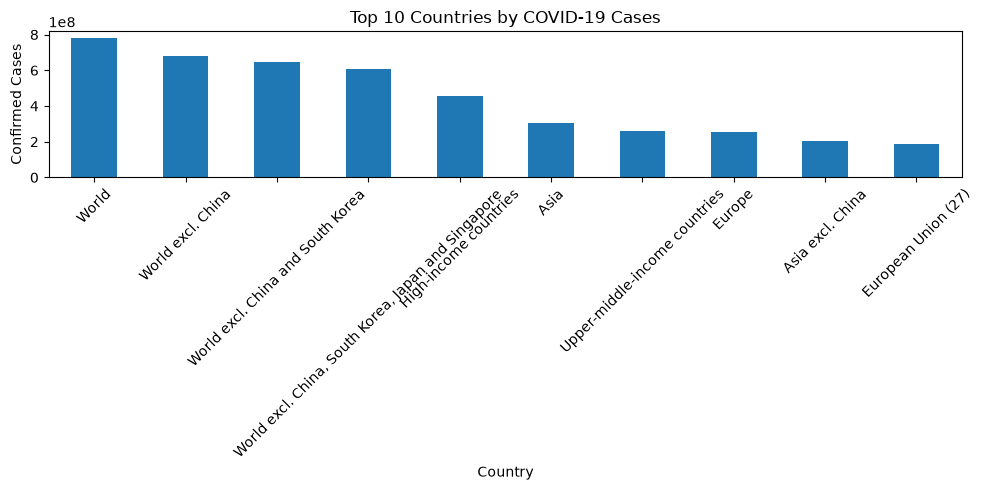

In [18]:
if cases_col is not None:
    top_countries = country_data.nlargest(10, cases_col)

    top_countries[cases_col].plot(
        kind="bar", figsize=(10, 5), title="Top 10 Countries by COVID-19 Cases"
    )

    plt.xlabel("Country")
    plt.ylabel("Confirmed Cases")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Confirmed cases column is not available.")

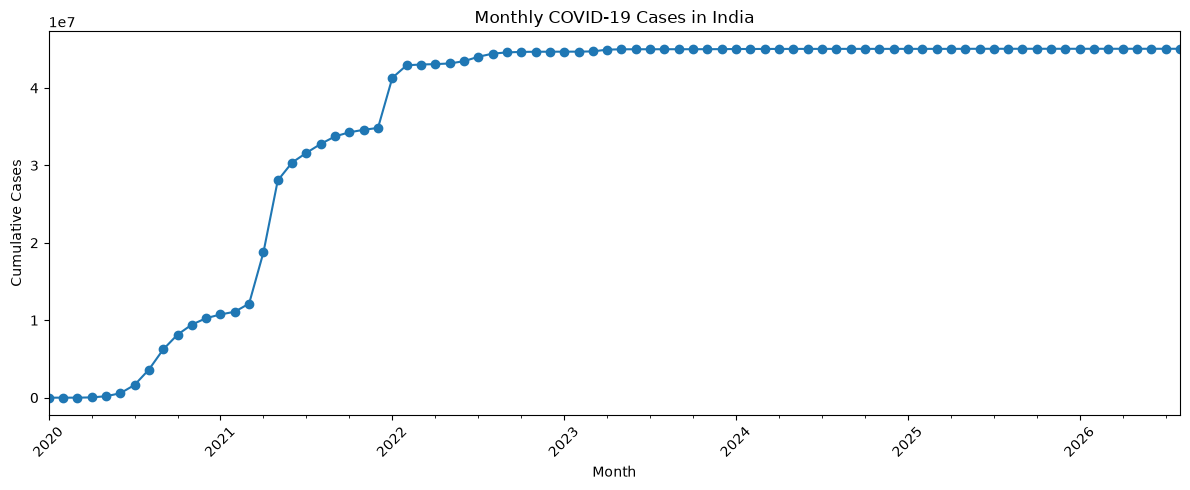

In [19]:
india = df[df[country_col].astype(str).str.lower() == "india"].copy()
india = india.sort_values(date_col)

if cases_col is not None:
    india["Month"] = india[date_col].dt.to_period("M")

    monthly = india.groupby("Month")[cases_col].max()

    monthly.plot(figsize=(12, 5), marker="o")
    plt.title("Monthly COVID-19 Cases in India")
    plt.xlabel("Month")
    plt.ylabel("Cumulative Cases")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

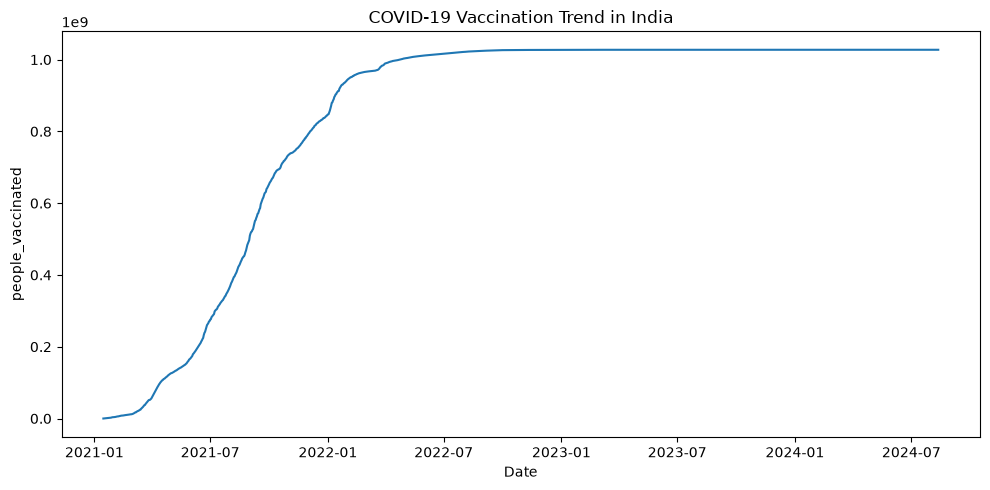

In [20]:
if vaccine_col is not None:
    vaccination = india.dropna(subset=[vaccine_col])

    plt.figure(figsize=(10, 5))
    plt.plot(vaccination[date_col], vaccination[vaccine_col])
    plt.title("COVID-19 Vaccination Trend in India")
    plt.xlabel("Date")
    plt.ylabel(vaccine_col)
    plt.tight_layout()
    plt.show()
else:
    print("Vaccination column is not available.")

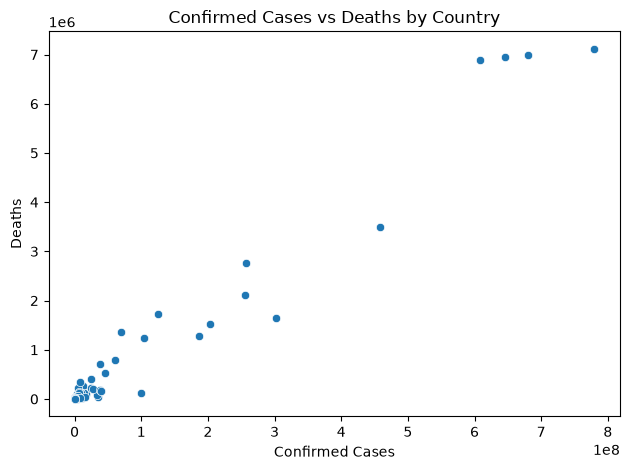

In [21]:
if cases_col is not None and deaths_col is not None:
    latest = (
        df.sort_values(date_col)
        .groupby(country_col)
        .tail(1)
        .dropna(subset=[cases_col, deaths_col])
    )

    sns.scatterplot(data=latest, x=cases_col, y=deaths_col)

    plt.title("Confirmed Cases vs Deaths by Country")
    plt.xlabel("Confirmed Cases")
    plt.ylabel("Deaths")
    plt.tight_layout()
    plt.show()

In [22]:
df.to_csv("covid_data_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# Project 2: Sales Data Analysis Dashboard

In [23]:
%pip install pandas numpy matplotlib seaborn plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\anshu\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [30]:
import pandas as pd

url = "https://raw.githubusercontent.com/Victory-Data/Superstore-Sales-Dataset/main/Sample%20-%20Superstore.csv"

df = pd.read_csv(url, encoding="latin1")

print(df.head())
print(df.shape)
print(df.columns.tolist())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [31]:
df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(df["Order Date"])
df = df.dropna()
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


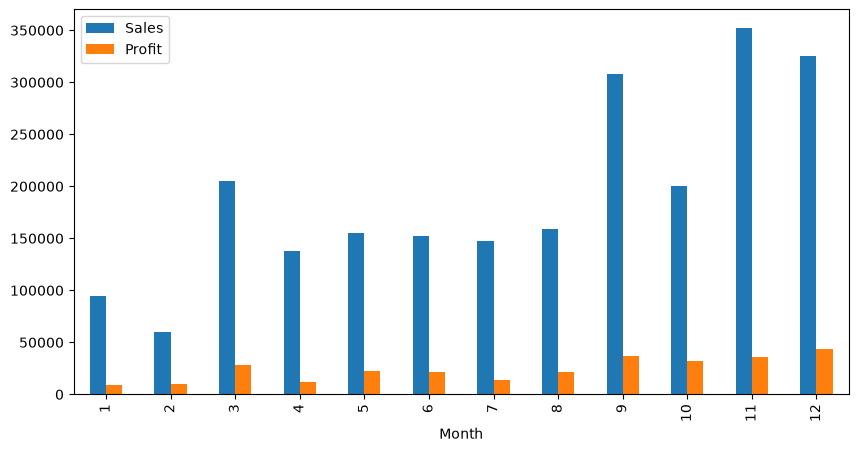

In [32]:
df["Month"] = df["Order Date"].dt.month

df.groupby("Month")[["Sales", "Profit"]].sum().plot(
    kind="bar", figsize=(10, 5)
)
plt.show()